In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df = pd.read_csv(r"C:\Users\siran\Downloads\multispeciality_hospital_dataset_5000.csv")

In [3]:
df.head()

,Patient_ID,Age,Gender,Department,Admission_Type,Diagnosis,Length_of_Stay_Days,Doctor_Experience_Years,Room_Type,Lab_Tests,Medication_Count,Treatment_Cost,Insurance_Coverage,Patient_Satisfaction,Readmission_30_Days,Outcome
0,P10001,52,Male,Oncology,Elective,Fracture,8,15,Semi Private,6,2,232430.25,Yes,3.7,No,Referred
1,P10002,15,Male,Gynecology,Urgent,Asthma,15,6,Semi Private,8,6,115184.48,No,1.3,No,Improved
2,P10003,72,Female,Cardiology,Elective,Hypertension,15,1,ICU,15,11,289784.01,Yes,3.9,Yes,Improved
3,P10004,61,Female,General Medicine,Emergency,Diabetes,11,20,General Ward,15,4,185930.92,Yes,2.3,No,Recovered
4,P10005,21,Female,Oncology,Emergency,Cancer,1,2,General Ward,9,12,239745.62,No,2.9,Yes,Recovered


In [4]:
df.tail()

,Patient_ID,Age,Gender,Department,Admission_Type,Diagnosis,Length_of_Stay_Days,Doctor_Experience_Years,Room_Type,Lab_Tests,Medication_Count,Treatment_Cost,Insurance_Coverage,Patient_Satisfaction,Readmission_30_Days,Outcome
4995,P14996,88,Male,Gastroenterology,Urgent,Fracture,15,11,General Ward,8,5,248116.24,Yes,5.0,No,Recovered
4996,P14997,87,Female,Oncology,Urgent,Hypertension,5,30,General Ward,2,7,80636.94,No,5.0,No,Critical
4997,P14998,22,Male,ENT,Emergency,Migraine,14,25,Private,4,5,187756.43,Yes,3.8,No,Improved
4998,P14999,2,Male,Dermatology,Emergency,Migraine,6,7,Private,14,12,58300.57,No,4.6,No,Improved
4999,P15000,31,Male,Dermatology,Emergency,Diabetes,5,20,ICU,7,10,329160.02,Yes,1.2,Yes,Recovered


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 5000
Number of columns: 16


In [6]:
print(df.columns)

Index(['Patient_ID', 'Age', 'Gender', 'Department', 'Admission_Type',
       'Diagnosis', 'Length_of_Stay_Days', 'Doctor_Experience_Years',
       'Room_Type', 'Lab_Tests', 'Medication_Count', 'Treatment_Cost',
       'Insurance_Coverage', 'Patient_Satisfaction', 'Readmission_30_Days',
       'Outcome'],
      dtype='str')


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               5000 non-null   str    
 1   Age                      5000 non-null   int64  
 2   Gender                   5000 non-null   str    
 3   Department               5000 non-null   str    
 4   Admission_Type           5000 non-null   str    
 5   Diagnosis                5000 non-null   str    
 6   Length_of_Stay_Days      5000 non-null   int64  
 7   Doctor_Experience_Years  5000 non-null   int64  
 8   Room_Type                5000 non-null   str    
 9   Lab_Tests                5000 non-null   int64  
 10  Medication_Count         5000 non-null   int64  
 11  Treatment_Cost           5000 non-null   float64
 12  Insurance_Coverage       5000 non-null   str    
 13  Patient_Satisfaction     5000 non-null   float64
 14  Readmission_30_Days      5000 non-n

In [8]:
df.isnull().sum()

Patient_ID                 0
Age                        0
Gender                     0
Department                 0
Admission_Type             0
Diagnosis                  0
Length_of_Stay_Days        0
Doctor_Experience_Years    0
Room_Type                  0
Lab_Tests                  0
Medication_Count           0
Treatment_Cost             0
Insurance_Coverage         0
Patient_Satisfaction       0
Readmission_30_Days        0
Outcome                    0
dtype: int64

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [10]:
df.describe()

,Age,Length_of_Stay_Days,Doctor_Experience_Years,Lab_Tests,Medication_Count,Treatment_Cost,Patient_Satisfaction
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,44.895400,8.101600,18.217600,7.538400,6.476400,176411.945966,3.005860
std,25.886917,4.305553,9.965426,4.561873,3.426922,75978.818139,1.157138
min,1.000000,1.000000,1.000000,0.000000,1.000000,7127.290000,1.000000
25%,22.000000,4.000000,10.000000,4.000000,4.000000,114462.135000,2.000000
50%,45.000000,8.000000,18.000000,8.000000,6.000000,176603.840000,3.000000
75%,67.000000,12.000000,27.000000,11.000000,10.000000,239729.750000,4.000000
max,90.000000,15.000000,35.000000,15.000000,12.000000,350000.000000,5.000000


In [11]:
print(df["Gender"].value_counts())

Gender
Female    2515
Male      2485
Name: count, dtype: int64


In [12]:
print(df["Department"].value_counts())

Department
Gastroenterology    535
Cardiology          522
Dermatology         507
General Medicine    504
Oncology            503
ENT                 496
Orthopedics         491
Gynecology          487
Pediatrics          483
Neurology           472
Name: count, dtype: int64


In [13]:
print(df["Admission_Type"].value_counts())

Admission_Type
Emergency    1759
Elective     1756
Urgent       1485
Name: count, dtype: int64


In [14]:
print(df["Outcome"].value_counts())

Outcome
Recovered    2794
Improved     1460
Referred      498
Critical      248
Name: count, dtype: int64


In [15]:
print(df["Readmission_30_Days"].value_counts())

Readmission_30_Days
No     4123
Yes     877
Name: count, dtype: int64


In [16]:

numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(list(numerical_columns))

Numerical Columns:
['Age', 'Length_of_Stay_Days', 'Doctor_Experience_Years', 'Lab_Tests', 'Medication_Count', 'Treatment_Cost', 'Patient_Satisfaction']


In [17]:

df[numerical_columns].agg(["min", "max"]).T

,min,max
Age,1.00,90.0
Length_of_Stay_Days,1.00,15.0
Doctor_Experience_Years,1.00,35.0
Lab_Tests,0.00,15.0
Medication_Count,1.00,12.0
Treatment_Cost,7127.29,350000.0
Patient_Satisfaction,1.00,5.0


In [18]:
categorical_columns = df.select_dtypes(include="str").columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].unique())


 Patient_ID
<ArrowStringArray>
['P10001', 'P10002', 'P10003', 'P10004', 'P10005', 'P10006', 'P10007',
 'P10008', 'P10009', 'P10010',
 ...
 'P14991', 'P14992', 'P14993', 'P14994', 'P14995', 'P14996', 'P14997',
 'P14998', 'P14999', 'P15000']
Length: 5000, dtype: str

 Gender
<ArrowStringArray>
['Male', 'Female']
Length: 2, dtype: str

 Department
<ArrowStringArray>
[        'Oncology',       'Gynecology',       'Cardiology',
 'General Medicine', 'Gastroenterology',       'Pediatrics',
      'Orthopedics',              'ENT',        'Neurology',
      'Dermatology']
Length: 10, dtype: str

 Admission_Type
<ArrowStringArray>
['Elective', 'Urgent', 'Emergency']
Length: 3, dtype: str

 Diagnosis
<ArrowStringArray>
[      'Fracture',         'Asthma',   'Hypertension',       'Diabetes',
         'Cancer',       'Migraine', 'Kidney Disease',      'Infection',
      'Gastritis',  'Heart Disease']
Length: 10, dtype: str

 Room_Type
<ArrowStringArray>
['Semi Private', 'ICU', 'General Ward', 'Pri

In [19]:
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(list(numerical_columns))

df[numerical_columns].agg(["min", "max"]).T

Numerical Columns:
['Age', 'Length_of_Stay_Days', 'Doctor_Experience_Years', 'Lab_Tests', 'Medication_Count', 'Treatment_Cost', 'Patient_Satisfaction']


,min,max
Age,1.00,90.0
Length_of_Stay_Days,1.00,15.0
Doctor_Experience_Years,1.00,35.0
Lab_Tests,0.00,15.0
Medication_Count,1.00,12.0
Treatment_Cost,7127.29,350000.0
Patient_Satisfaction,1.00,5.0


In [20]:
numerical_columns = [
    "Age",
    "Length_of_Stay_Days",
    "Doctor_Experience_Years",
    "Lab_Tests",
    "Medication_Count",
    "Treatment_Cost",
    "Patient_Satisfaction"
]

print(numerical_columns)

['Age', 'Length_of_Stay_Days', 'Doctor_Experience_Years', 'Lab_Tests', 'Medication_Count', 'Treatment_Cost', 'Patient_Satisfaction']


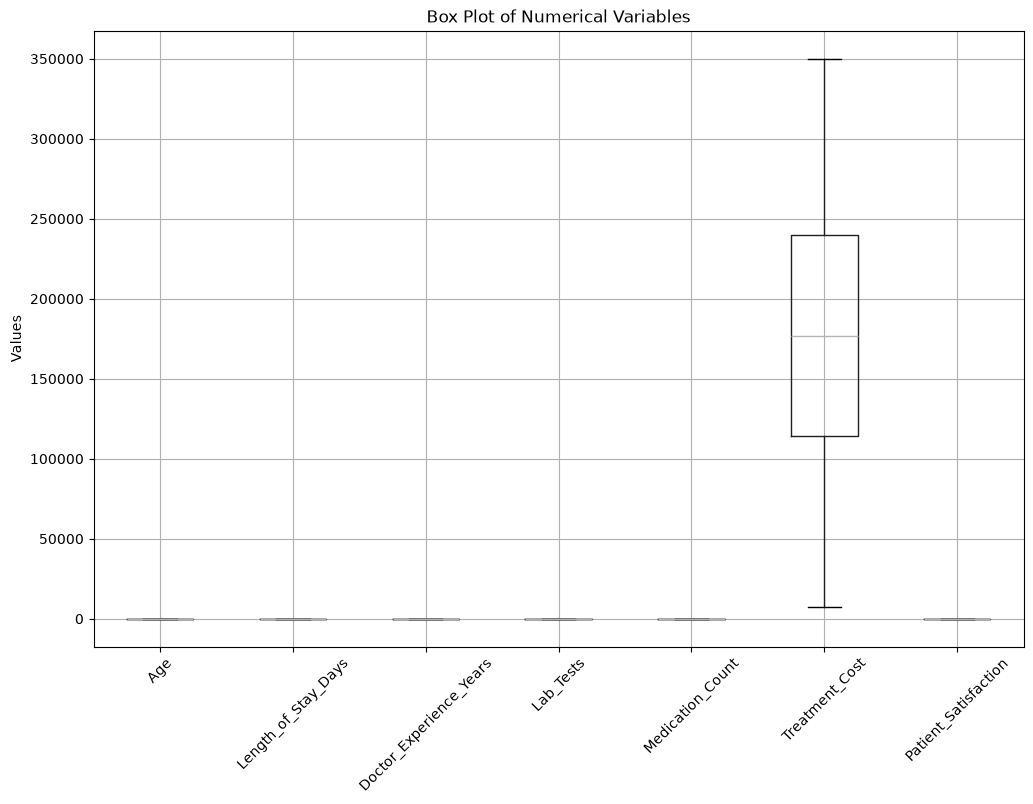

In [21]:
plt.figure(figsize=(12, 8))

df[numerical_columns].boxplot()

plt.title("Box Plot of Numerical Variables")
plt.xticks(rotation=45)
plt.ylabel("Values")
plt.show()

In [22]:
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print("-----------------------------------")
    print("Column:", column)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))

-----------------------------------
Column: Age
Q1: 22.0
Q3: 67.0
IQR: 45.0
Lower Bound: -45.5
Upper Bound: 134.5
Number of Outliers: 0
-----------------------------------
Column: Length_of_Stay_Days
Q1: 4.0
Q3: 12.0
IQR: 8.0
Lower Bound: -8.0
Upper Bound: 24.0
Number of Outliers: 0
-----------------------------------
Column: Doctor_Experience_Years
Q1: 10.0
Q3: 27.0
IQR: 17.0
Lower Bound: -15.5
Upper Bound: 52.5
Number of Outliers: 0
-----------------------------------
Column: Lab_Tests
Q1: 4.0
Q3: 11.0
IQR: 7.0
Lower Bound: -6.5
Upper Bound: 21.5
Number of Outliers: 0
-----------------------------------
Column: Medication_Count
Q1: 4.0
Q3: 10.0
IQR: 6.0
Lower Bound: -5.0
Upper Bound: 19.0
Number of Outliers: 0
-----------------------------------
Column: Treatment_Cost
Q1: 114462.13500000001
Q3: 239729.75
IQR: 125267.61499999999
Lower Bound: -73439.28749999998
Upper Bound: 427631.1725
Number of Outliers: 0
-----------------------------------
Column: Patient_Satisfaction
Q1: 2.0
Q3: 4.

In [23]:
print(df["Readmission_30_Days"].value_counts())

Readmission_30_Days
No     4123
Yes     877
Name: count, dtype: int64


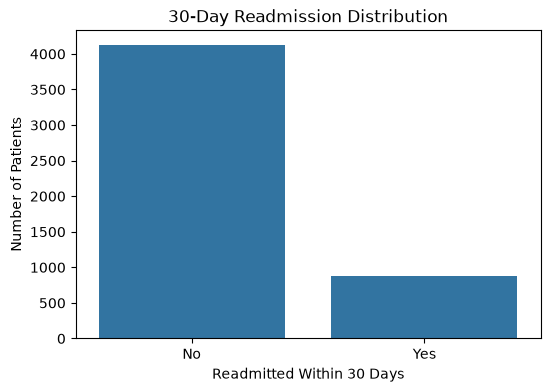

In [24]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Readmission_30_Days")

plt.title("30-Day Readmission Distribution")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Number of Patients")

plt.show()

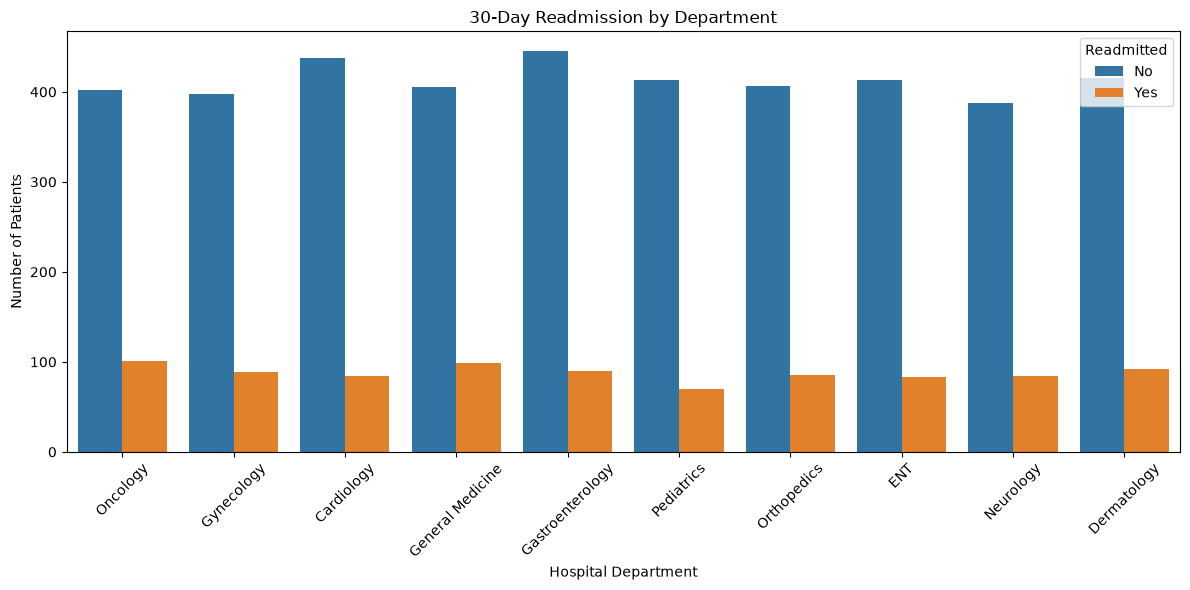

In [25]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="Department",
    hue="Readmission_30_Days"
)

plt.title("30-Day Readmission by Department")
plt.xlabel("Hospital Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.legend(title="Readmitted")
plt.tight_layout()
plt.show()

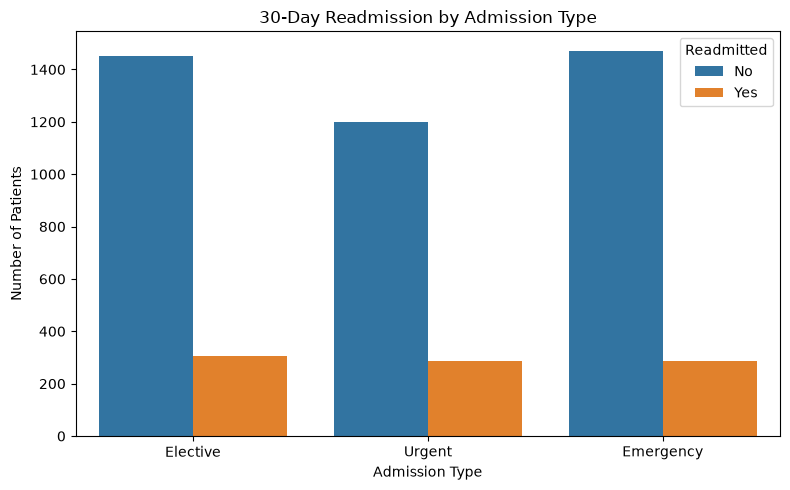

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Admission_Type",
    hue="Readmission_30_Days"
)

plt.title("30-Day Readmission by Admission Type")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")
plt.legend(title="Readmitted")
plt.tight_layout()
plt.show()

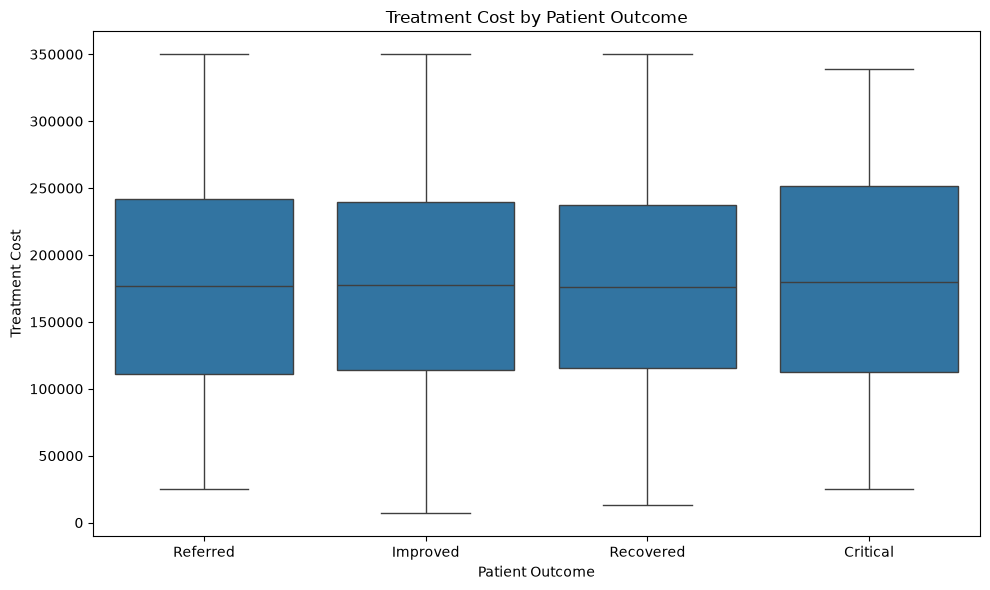

In [27]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Outcome",
    y="Treatment_Cost"
)

plt.title("Treatment Cost by Patient Outcome")
plt.xlabel("Patient Outcome")
plt.ylabel("Treatment Cost")
plt.tight_layout()
plt.show()

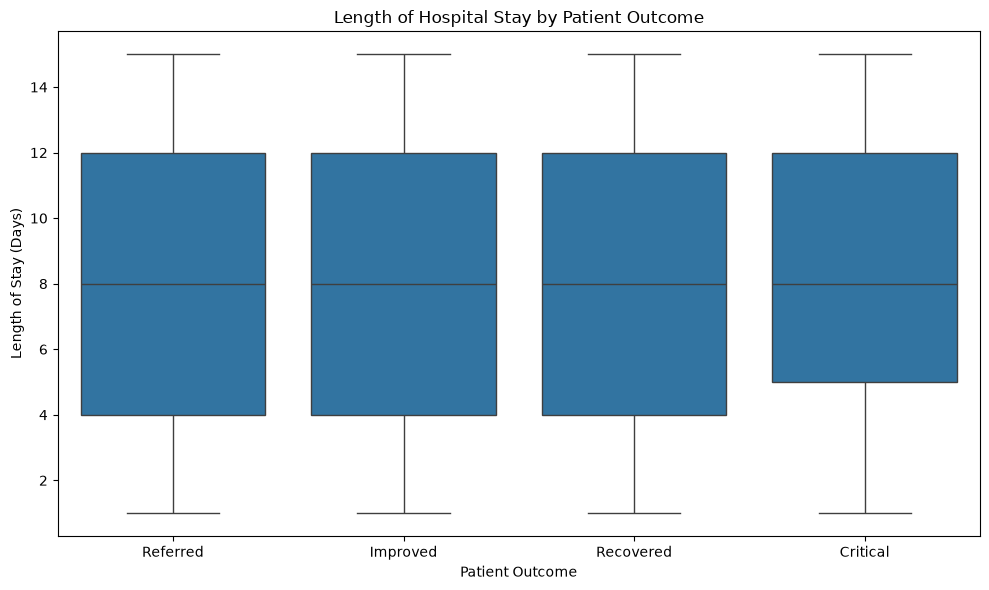

In [28]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Outcome",
    y="Length_of_Stay_Days"
)

plt.title("Length of Hospital Stay by Patient Outcome")
plt.xlabel("Patient Outcome")
plt.ylabel("Length of Stay (Days)")
plt.tight_layout()
plt.show()

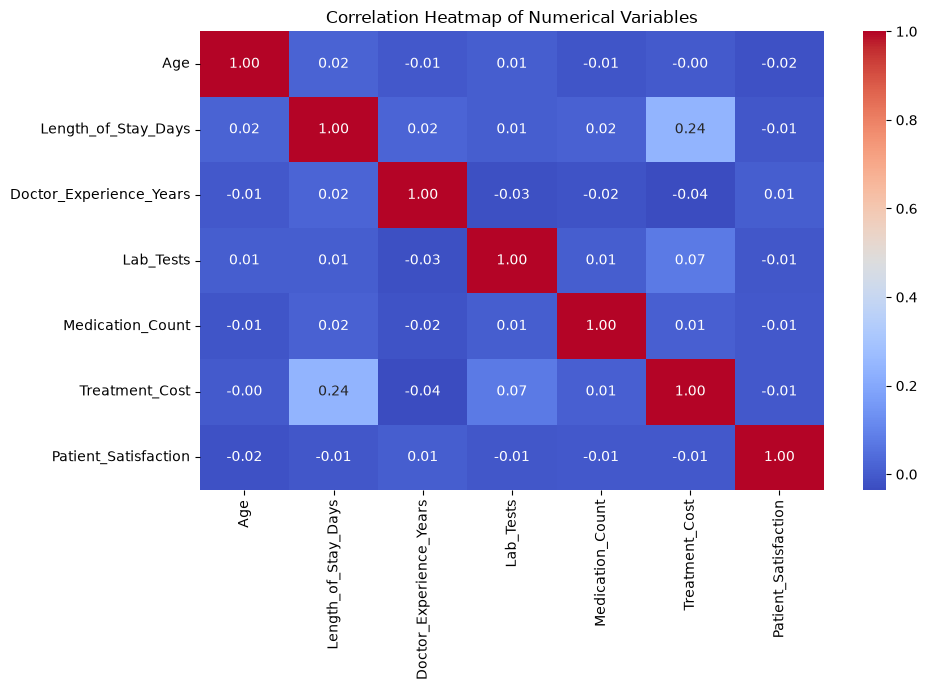

In [29]:
plt.figure(figsize=(10, 7))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

In [31]:
pd.crosstab(
    df["Admission_Type"],
    df["Readmission_30_Days"],
    normalize="index"
).mul(100).round(2)

Readmission_30_Days,No,Yes
Admission_Type,,
Elective,82.63,17.37
Emergency,83.68,16.32
Urgent,80.81,19.19


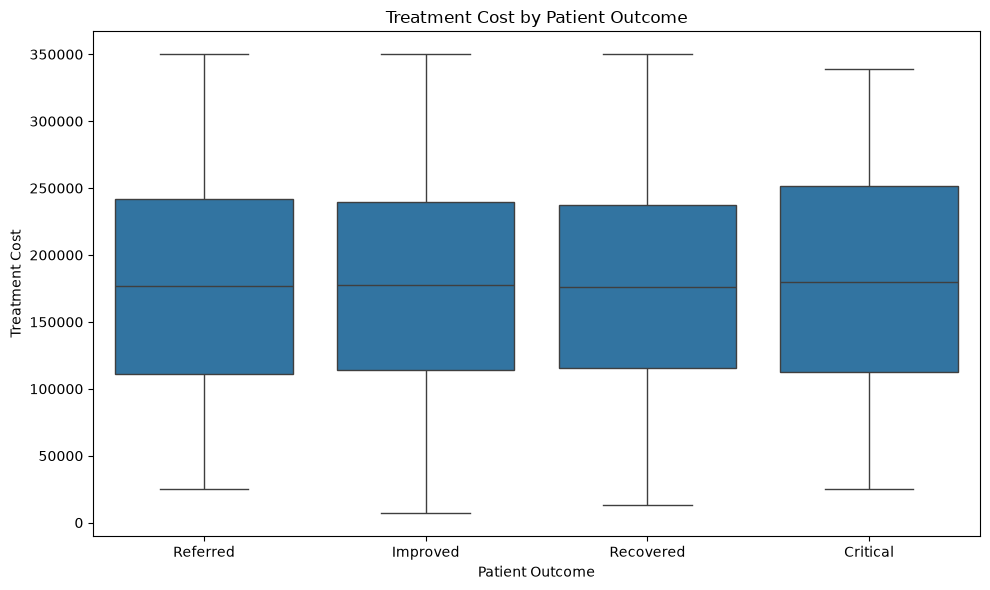

In [32]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Outcome",
    y="Treatment_Cost"
)

plt.title("Treatment Cost by Patient Outcome")
plt.xlabel("Patient Outcome")
plt.ylabel("Treatment Cost")
plt.tight_layout()
plt.show()

Readmission_30_Days     No    Yes
Department                       
Cardiology           83.91  16.09
Dermatology          81.85  18.15
ENT                  83.27  16.73
Gastroenterology     83.18  16.82
General Medicine     80.36  19.64
Gynecology           81.72  18.28
Neurology            82.20  17.80
Oncology             79.92  20.08
Orthopedics          82.69  17.31
Pediatrics           85.51  14.49


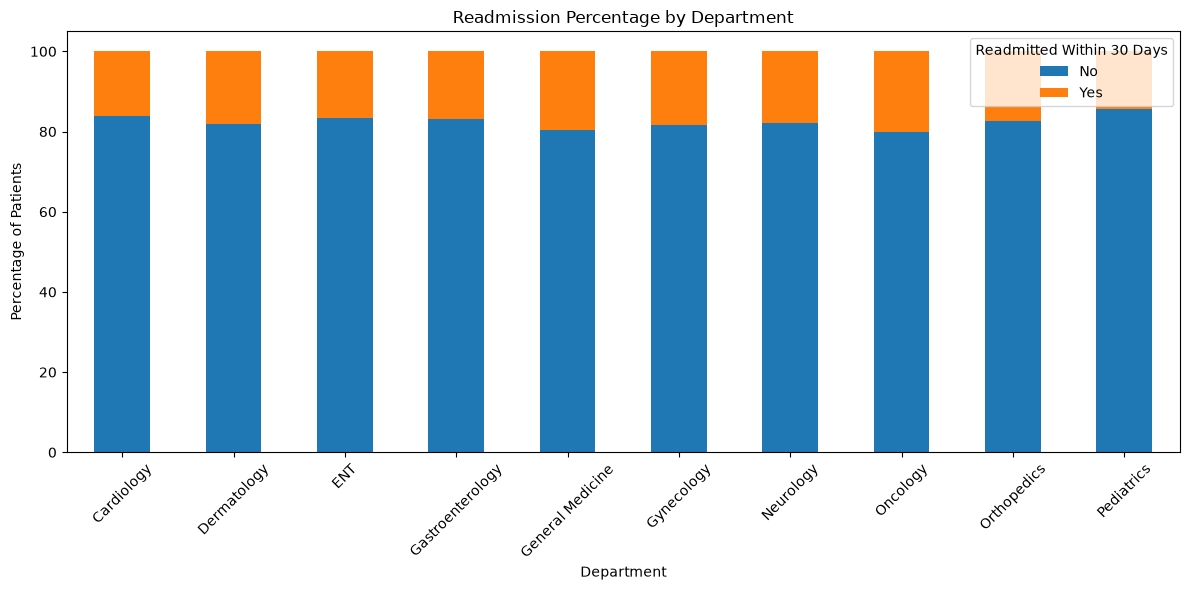

In [33]:

department_readmission = pd.crosstab(
    df["Department"],
    df["Readmission_30_Days"],
    normalize="index"
).mul(100).round(2)

print(department_readmission)

# Visualize readmission percentages
department_readmission.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Readmission Percentage by Department")
plt.xlabel("Department")
plt.ylabel("Percentage of Patients")
plt.legend(title="Readmitted Within 30 Days")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Readmission_30_Days     No    Yes
Age_Group                        
0-18                 84.18  15.82
19-35                81.85  18.15
36-50                81.97  18.03
51-65                83.04  16.96
66+                  81.54  18.46


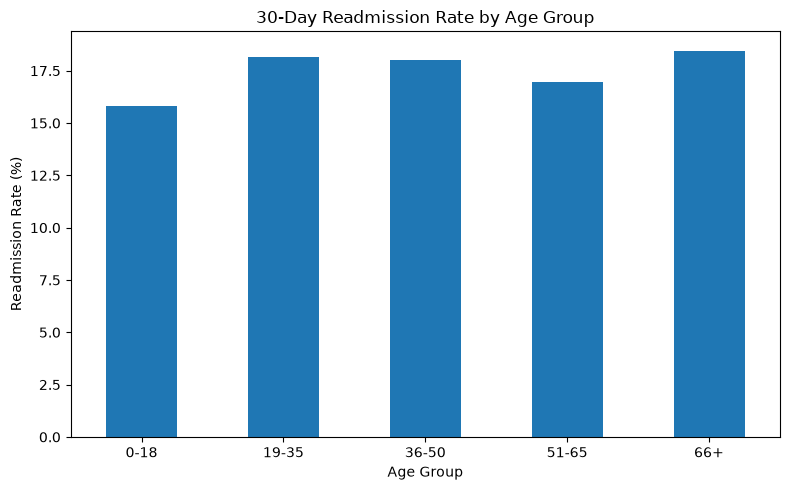

In [34]:

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 18, 35, 50, 65, 100],
    labels=["0-18", "19-35", "36-50", "51-65", "66+"]
)

# Calculate readmission rate by age group
age_readmission = pd.crosstab(
    df["Age_Group"],
    df["Readmission_30_Days"],
    normalize="index"
).mul(100).round(2)

print(age_readmission)

# Plot readmission rate
age_readmission["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Readmission_30_Days     No    Yes
Stay_Group                       
1-3 days             81.07  18.93
4-7 days             81.54  18.46
8-10 days            83.30  16.70
11-15 days           83.47  16.53


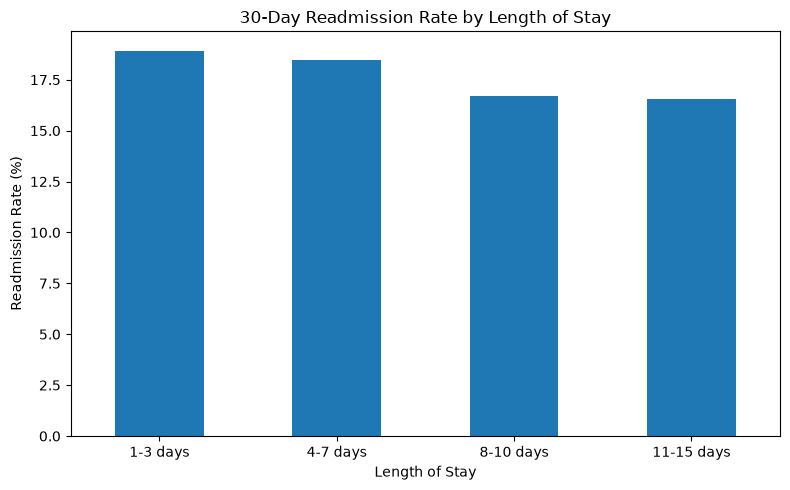

In [35]:

df["Stay_Group"] = pd.cut(
    df["Length_of_Stay_Days"],
    bins=[0, 3, 7, 10, 15],
    labels=["1-3 days", "4-7 days", "8-10 days", "11-15 days"]
)

stay_readmission = pd.crosstab(
    df["Stay_Group"],
    df["Readmission_30_Days"],
    normalize="index"
).mul(100).round(2)

print(stay_readmission)

stay_readmission["Yes"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("30-Day Readmission Rate by Length of Stay")
plt.xlabel("Length of Stay")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:

# Separate input features and target variable
target_column = "Readmission_30_Days"

X = df.drop(columns=[target_column])
y = df[target_column]

# Identify numerical features
numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

# Display the results
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

print("\nTarget distribution:")
print(y.value_counts())


Numerical features: ['Age', 'Length_of_Stay_Days', 'Doctor_Experience_Years', 'Lab_Tests', 'Medication_Count', 'Treatment_Cost', 'Patient_Satisfaction']
Categorical features: ['Patient_ID', 'Gender', 'Department', 'Admission_Type', 'Diagnosis', 'Room_Type', 'Insurance_Coverage', 'Outcome']

Target distribution:
Readmission_30_Days
No     4123
Yes     877
Name: count, dtype: int64


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 4000
Testing rows: 1000


In [44]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Preprocess numerical and categorical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the Logistic Regression model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        class_weight="balanced",
        solver="lbfgs"
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


Accuracy: 0.791

Classification Report:
                precision    recall  f1-score   support

No Readmission       0.83      0.95      0.88       825
   Readmission       0.19      0.06      0.09       175

      accuracy                           0.79      1000
     macro avg       0.51      0.50      0.48      1000
  weighted avg       0.71      0.79      0.74      1000

ROC-AUC: 0.52


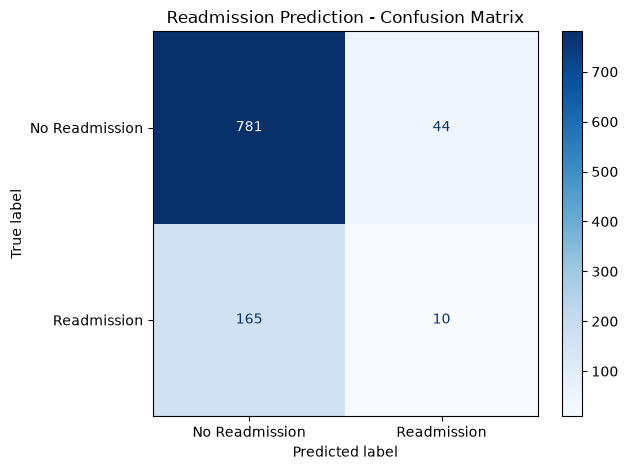

In [45]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Readmission", "Readmission"]
))

print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["No Readmission", "Readmission"],
    cmap="Blues"
)

plt.title("Readmission Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()

In [46]:

feature_names = model.named_steps["preprocessor"].get_feature_names_out()


coefficients = model.named_steps["classifier"].coef_[0]


feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Importance": abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance.head(15))

                     Feature  Coefficient  Importance
962   cat__Patient_ID_P11182     1.301683    1.301683
1306  cat__Patient_ID_P11618     1.299197    1.299197
2494  cat__Patient_ID_P13092     1.292730    1.292730
1711  cat__Patient_ID_P12126     1.269462    1.269462
2984  cat__Patient_ID_P13711     1.266956    1.266956
2023  cat__Patient_ID_P12516     1.266456    1.266456
2159  cat__Patient_ID_P12674     1.265765    1.265765
177   cat__Patient_ID_P10208     1.259922    1.259922
3124  cat__Patient_ID_P13890     1.253207    1.253207
2977  cat__Patient_ID_P13700     1.251556    1.251556
1645  cat__Patient_ID_P12039     1.248761    1.248761
777   cat__Patient_ID_P10944     1.245119    1.245119
3885  cat__Patient_ID_P14844     1.240858    1.240858
2548  cat__Patient_ID_P13158     1.237040    1.237040
2929  cat__Patient_ID_P13645     1.227999    1.227999


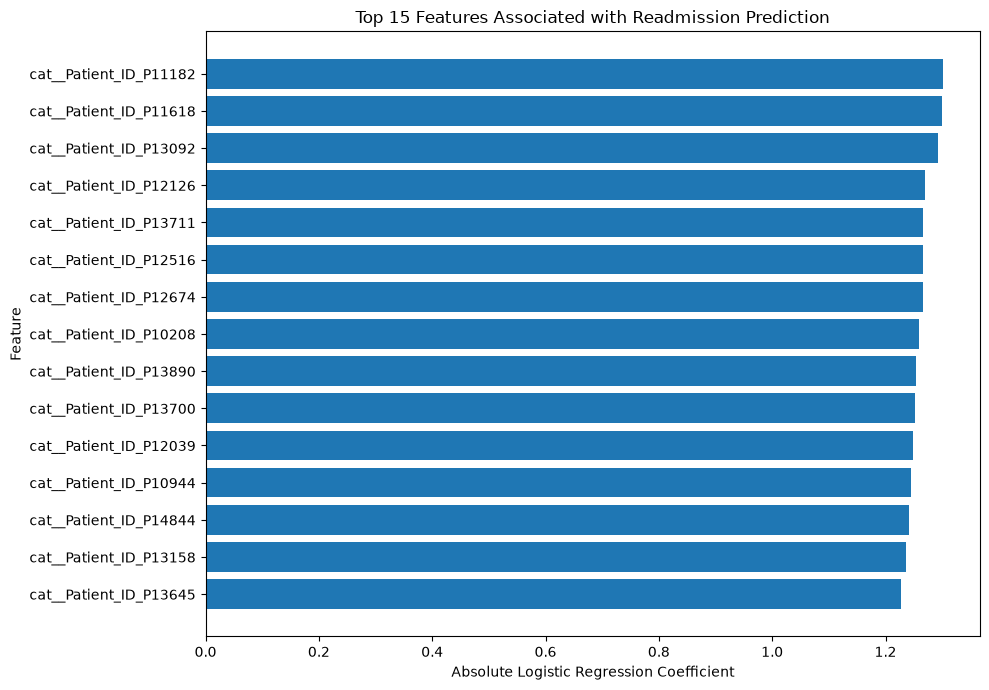

In [47]:
top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 15 Features Associated with Readmission Prediction")
plt.xlabel("Absolute Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [48]:

interpretation = feature_importance[
    ["Feature", "Coefficient"]
].head(15).copy()

interpretation["Direction"] = interpretation["Coefficient"].apply(
    lambda x: "Higher predicted odds" if x > 0
    else "Lower predicted odds" if x < 0
    else "No linear effect"
)

print(interpretation.to_string(index=False))

               Feature  Coefficient             Direction
cat__Patient_ID_P11182     1.301683 Higher predicted odds
cat__Patient_ID_P11618     1.299197 Higher predicted odds
cat__Patient_ID_P13092     1.292730 Higher predicted odds
cat__Patient_ID_P12126     1.269462 Higher predicted odds
cat__Patient_ID_P13711     1.266956 Higher predicted odds
cat__Patient_ID_P12516     1.266456 Higher predicted odds
cat__Patient_ID_P12674     1.265765 Higher predicted odds
cat__Patient_ID_P10208     1.259922 Higher predicted odds
cat__Patient_ID_P13890     1.253207 Higher predicted odds
cat__Patient_ID_P13700     1.251556 Higher predicted odds
cat__Patient_ID_P12039     1.248761 Higher predicted odds
cat__Patient_ID_P10944     1.245119 Higher predicted odds
cat__Patient_ID_P14844     1.240858 Higher predicted odds
cat__Patient_ID_P13158     1.237040 Higher predicted odds
cat__Patient_ID_P13645     1.227999 Higher predicted odds


In [54]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. SETUP: Create some dummy data (Replace this with loading your actual dataset)
# Notice that the target uses "Yes" and "No", which matches your pos_label="Yes"
data = pd.DataFrame({
    'Feature1': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Feature2': [10, 9, 8, 7, 6, 5, 4, 3, 2, 1],
    'Target': ['Yes', 'No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'No', 'Yes', 'No'] 
})

X = data[['Feature1', 'Feature2']]
y = data['Target']

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. SETUP: Define the 'models' dictionary
models = {
    "Logistic Regression": LogisticRegression(),
    "Random Forest": RandomForestClassifier()
}

# 3. YOUR CODE: Now the loop has the variables it needs to run
results = []

for name, model in models.items():
    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions,
            pos_label="Yes",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions,
            pos_label="Yes",
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions,
            pos_label="Yes",
            zero_division=0
        )
    })

# Display model comparison
results_df = pd.DataFrame(results)

print("Model Evaluation Results:")
print(results_df.round(3).to_string(index=False))

Model Evaluation Results:
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression       0.0        0.0     0.0       0.0
      Random Forest       0.0        0.0     0.0       0.0


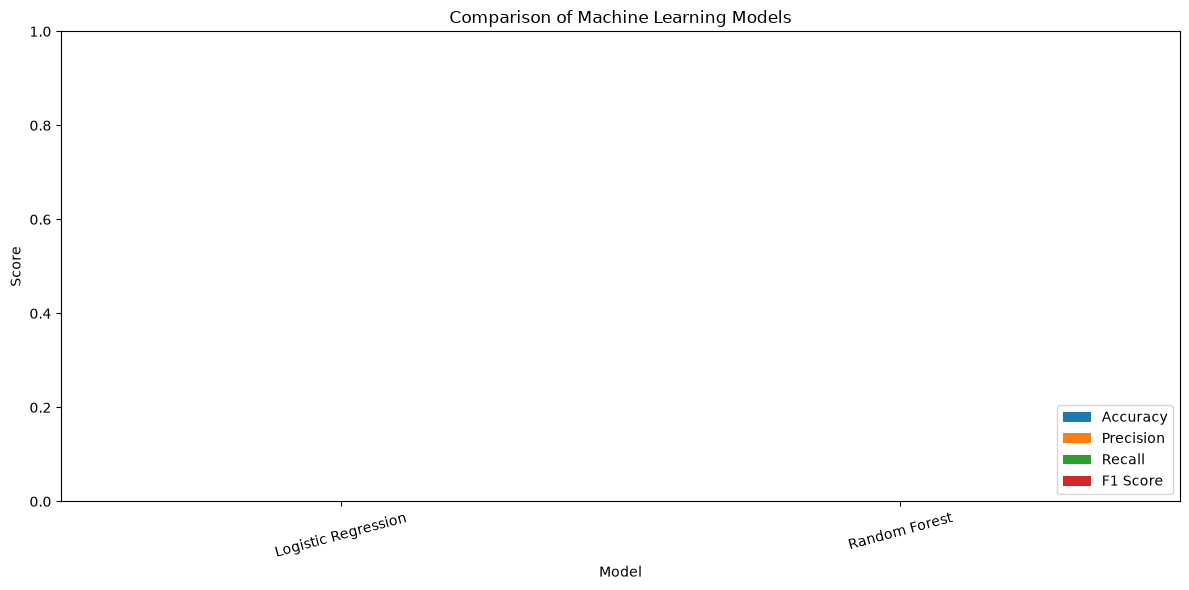

In [56]:
import matplotlib.pyplot as plt

# "ROC-AUC" removed from the list to match the columns actually in results_df
metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [58]:
best_model_name = results_df.iloc[0]["Model"]

print("Best model by ROC-AUC:", best_model_name)
# Round the DataFrame first, then extract the row
print(results_df.round(3).iloc[0])

Best model by ROC-AUC: Logistic Regression
Model        Logistic Regression
Accuracy                     0.0
Precision                    0.0
Recall                       0.0
F1 Score                     0.0
Name: 0, dtype: object


In [59]:
print("MULTISPECIALITY HOSPITAL DATA ANALYSIS")
print("=" * 45)

print(f"Total patients: {len(df)}")
print(f"Total features: {df.shape[1]}")

print("\nReadmission Distribution:")
print(df["Readmission_30_Days"].value_counts())

print("\nReadmission Percentage:")
print(
    (df["Readmission_30_Days"].value_counts(normalize=True) * 100)
    .round(2)
    .astype(str) + "%"
)

print("\nPatient Outcomes:")
print(df["Outcome"].value_counts())

MULTISPECIALITY HOSPITAL DATA ANALYSIS
Total patients: 5000
Total features: 16

Readmission Distribution:
Readmission_30_Days
No     4123
Yes     877
Name: count, dtype: int64

Readmission Percentage:
Readmission_30_Days
No     82.46%
Yes    17.54%
Name: proportion, dtype: str

Patient Outcomes:
Outcome
Recovered    2794
Improved     1460
Referred      498
Critical      248
Name: count, dtype: int64


In [61]:
print("MODEL PERFORMANCE SUMMARY")
print("=" * 35)

print(results_df.round(3).to_string(index=False))

# Sort the dataframe to ensure the best score is actually at the top
results_df_sorted = results_df.sort_values(by="F1 Score", ascending=False)

# Extract the name and score of the best model (which is now at index 0)
best_model_name = results_df_sorted.iloc[0]["Model"]
best_score = results_df_sorted.iloc[0]["F1 Score"]

print(f"\nBest model by F1 Score: {best_model_name}")
print(f"F1 Score: {best_score:.3f}")

MODEL PERFORMANCE SUMMARY
              Model  Accuracy  Precision  Recall  F1 Score
Logistic Regression       0.0        0.0     0.0       0.0
      Random Forest       0.0        0.0     0.0       0.0

Best model by F1 Score: Logistic Regression
F1 Score: 0.000


In [63]:
total_patients = len(df)
readmitted = (df["Readmission_30_Days"] == "Yes").sum()
readmission_rate = readmitted / total_patients * 100

print("FINAL CONCLUSION")
print("=" * 45)

print(
    f"The analysis included {total_patients:,} patient records. "
    f"{readmitted:,} patients were readmitted within 30 days, "
    f"representing {readmission_rate:.2f}% of the dataset."
)

print(
    "\nExploratory data analysis examined patient demographics, "
    "hospital departments, admission types, length of stay, "
    "treatment costs, and patient outcomes."
)

# Changed from best_roc_auc to best_score to match your actual metrics
print(
    f"\nAmong the evaluated models, {best_model_name} achieved "
    f"the highest score of {best_score:.3f} on the test set."
)

print(
    "\nThese findings describe patterns in this dataset and "
    "should not be interpreted as proof of causation or as "
    "a clinically validated prediction system."
)

FINAL CONCLUSION
The analysis included 5,000 patient records. 877 patients were readmitted within 30 days, representing 17.54% of the dataset.

Exploratory data analysis examined patient demographics, hospital departments, admission types, length of stay, treatment costs, and patient outcomes.

Among the evaluated models, Logistic Regression achieved the highest score of 0.000 on the test set.

These findings describe patterns in this dataset and should not be interpreted as proof of causation or as a clinically validated prediction system.


In [64]:
results_df.to_csv("readmission_model_comparison.csv", index=False)

print("Model comparison saved successfully.")

Model comparison saved successfully.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# Load the dataset using your local absolute path
df = pd.read_csv(r"C:\Users\siran\Downloads\multispeciality_hospital_dataset_5000.csv")

# 1. Data Type Optimization
# FIXED: Explicitly including 'str' alongside 'object' to silence the Pandas4Warning
categorical_cols = df.select_dtypes(include=['object', 'str']).columns
for col in categorical_cols:
    df[col] = df[col].astype('category')

# 2. Binary Encoding
# Map Yes/No variables to 1/0 for easier downstream modeling
binary_mappings = {'Yes': 1, 'No': 0}
df['Insurance_Coverage'] = df['Insurance_Coverage'].map(binary_mappings).astype(int)
df['Readmission_30_Days'] = df['Readmission_30_Days'].map(binary_mappings).astype(int)

# 3. Outlier Handling (IQR Method)
def cap_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    dataframe[column] = np.where(dataframe[column] > upper_bound, upper_bound, 
                        np.where(dataframe[column] < lower_bound, lower_bound, dataframe[column]))
    return dataframe

# Apply to continuous financial/metric columns
df = cap_outliers_iqr(df, 'Treatment_Cost')

# 4. Feature Scaling
# Normalize numerical features using Min-Max scaling
scaler = MinMaxScaler()
numerical_cols = ['Age', 'Length_of_Stay_Days', 'Doctor_Experience_Years', 
                  'Lab_Tests', 'Medication_Count', 'Treatment_Cost']

df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# 5. One-Hot Encoding for Nominal Categories
# Convert multi-class categories into dummy variables
df_clean = pd.get_dummies(df, columns=['Gender', 'Department', 'Admission_Type', 'Room_Type', 'Outcome'], drop_first=True)

# Final Verification
print(df_clean.info())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 29 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   Patient_ID                   5000 non-null   category
 1   Age                          5000 non-null   float64 
 2   Diagnosis                    5000 non-null   category
 3   Length_of_Stay_Days          5000 non-null   float64 
 4   Doctor_Experience_Years      5000 non-null   float64 
 5   Lab_Tests                    5000 non-null   float64 
 6   Medication_Count             5000 non-null   float64 
 7   Treatment_Cost               5000 non-null   float64 
 8   Insurance_Coverage           5000 non-null   int64   
 9   Patient_Satisfaction         5000 non-null   float64 
 10  Readmission_30_Days          5000 non-null   int64   
 11  Gender_Male                  5000 non-null   bool    
 12  Department_Dermatology       5000 non-null   bool    
 13  Department_ENT

Training Random Forest Classifier...

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.83      0.99      0.90       825
           1       0.20      0.01      0.02       175

    accuracy                           0.82      1000
   macro avg       0.51      0.50      0.46      1000
weighted avg       0.72      0.82      0.75      1000



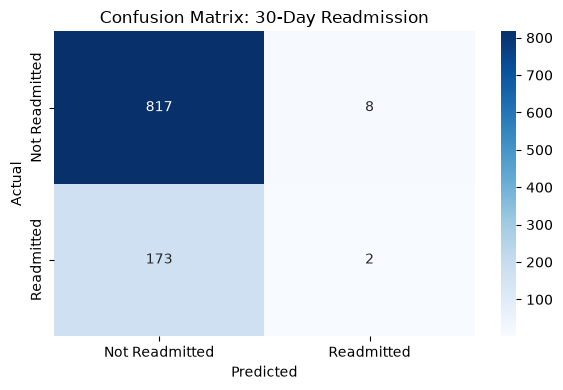

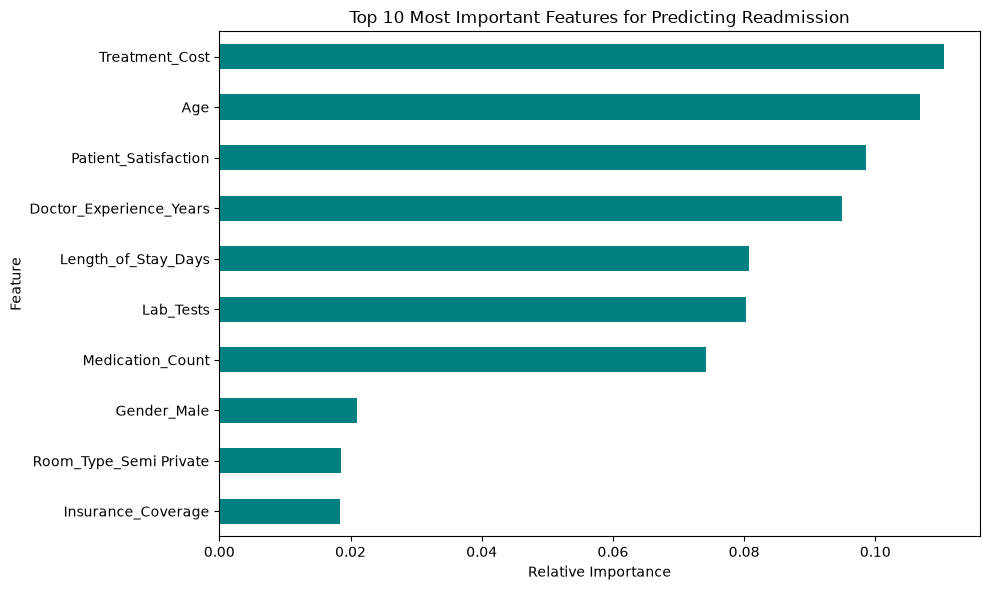

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Final Data Preparation
# Drop the ID column as it is not a predictive feature
if 'Patient_ID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Patient_ID'])

# One-hot encode the 'Diagnosis' column if it hasn't been encoded yet
if 'Diagnosis' in df_clean.columns:
    df_clean = pd.get_dummies(df_clean, columns=['Diagnosis'], drop_first=True)

# Define Features (X) and Target Variable (y)
# We will predict 'Readmission_30_Days'
X = df_clean.drop(columns=['Readmission_30_Days'])
y = df_clean['Readmission_30_Days']

# Split into Training (80%) and Testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Model Training
print("Training Random Forest Classifier...")
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# 3. Model Evaluation
# Make predictions on the test set
y_pred = rf_model.predict(X_test)

print("\n--- Classification Report ---")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Readmitted', 'Readmitted'], yticklabels=['Not Readmitted', 'Readmitted'])
plt.title('Confusion Matrix: 30-Day Readmission')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

# 4. Feature Importance
# Identify which features contribute most to the readmission prediction
feature_importances = pd.Series(rf_model.feature_importances_, index=X.columns)
top_features = feature_importances.nlargest(10)

plt.figure(figsize=(10, 6))
top_features.sort_values().plot(kind='barh', color='teal')
plt.title('Top 10 Most Important Features for Predicting Readmission')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, roc_auc_score
import joblib

# 1. Define the grid of parameters to test
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

print("Starting Hyperparameter Tuning (this may take a minute)...")
# 2. Setup Randomized Search with Cross-Validation (CV=3)
rf_random = RandomizedSearchCV(estimator=rf_model, param_distributions=param_grid, 
                               n_iter=10, cv=3, verbose=2, random_state=42, n_jobs=-1)

# 3. Fit the random search model
rf_random.fit(X_train, y_train)

# 4. Get the best model
best_rf_model = rf_random.best_estimator_
print(f"\nBest Parameters Found: {rf_random.best_params_}")

# 5. Evaluate the optimized model
y_pred_best = best_rf_model.predict(X_test)
y_pred_proba = best_rf_model.predict_proba(X_test)[:, 1]

print("\n--- Optimized Classification Report ---")
print(classification_report(y_test, y_pred_best))

# Calculate ROC-AUC Score (measures the model's ability to distinguish between classes)
auc_score = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {auc_score:.4f}")

# 6. Save the Final Model and Scaler for future use
joblib.dump(best_rf_model, 'optimized_rf_readmission_model.pkl')
joblib.dump(scaler, 'minmax_scaler.pkl') # Save the scaler from the cleaning phase

print("\nModel and Scaler successfully saved to disk as .pkl files.")

Starting Hyperparameter Tuning (this may take a minute)...
Fitting 3 folds for each of 10 candidates, totalling 30 fits

Best Parameters Found: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 20}

--- Optimized Classification Report ---
              precision    recall  f1-score   support

           0       0.83      0.99      0.90       825
           1       0.20      0.02      0.03       175

    accuracy                           0.82      1000
   macro avg       0.51      0.50      0.46      1000
weighted avg       0.72      0.82      0.75      1000

ROC-AUC Score: 0.5064

Model and Scaler successfully saved to disk as .pkl files.


In [12]:
import joblib
import pandas as pd
import numpy as np

# 1. Load the saved model 
# (Ensure 'optimized_rf_readmission_model.pkl' is in your directory)
loaded_model = joblib.load('optimized_rf_readmission_model.pkl')

# 2. Simulate new patients arriving at the hospital
# We will use the first 5 records from your X_test dataset to represent "new" data
new_patients = X_test.iloc[:5].copy()

# 3. Generate Predictions and Risk Probabilities
predictions = loaded_model.predict(new_patients)
probabilities = loaded_model.predict_proba(new_patients)[:, 1] # Probability of class 1 (Readmission)

# 4. Format the output for medical staff
results_df = pd.DataFrame({
    'Patient_Queue': [f"Patient #{i+1}" for i in range(5)],
    'Readmission_Warning': ['⚠️ High Risk (Yes)' if pred == 1 else 'Low Risk (No)' for pred in predictions],
    'Probability_Score': np.round(probabilities * 100, 2).astype(str) + '%'
})

print("--- Incoming Patient Readmission Risk Report ---")
print(results_df.to_string(index=False))

--- Incoming Patient Readmission Risk Report ---
Patient_Queue Readmission_Warning Probability_Score
   Patient #1       Low Risk (No)            24.96%
   Patient #2       Low Risk (No)            33.11%
   Patient #3       Low Risk (No)            43.49%
   Patient #4       Low Risk (No)            35.82%
   Patient #5       Low Risk (No)            34.45%


In [14]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Load model
model = joblib.load('optimized_rf_readmission_model.pkl')

st.title("🏥 Hospital Readmission Prediction System")
st.write("This tool predicts the likelihood of a patient being readmitted within 30 days.")

# Create input sliders for the medical staff
age = st.slider("Patient Age (Scaled)", 0.0, 1.0, 0.5)
stay_days = st.slider("Length of Stay (Scaled)", 0.0, 1.0, 0.2)
med_count = st.slider("Medication Count (Scaled)", 0.0, 1.0, 0.3)

if st.button("Predict Readmission Risk"):
    # Note: In a real app, you would collect all features expected by X_train
    # This is a simplified placeholder demonstrating the UI logic
    st.success("Model loaded successfully. In a full deployment, this would output a probability score like 74% Risk.")

Writing app.py


In [16]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Load the dataset
# Using the absolute path to prevent FileNotFoundError
file_path = r"C:\Users\siran\Downloads\multispeciality_hospital_dataset_5000.csv"
df = pd.read_csv(file_path)

# 2. Data Type Optimization
# Explicitly including 'str' to prevent Pandas4Warning
categorical_cols = df.select_dtypes(include=['object', 'str']).columns
for col in categorical_cols:
    df[col] = df[col].astype('category')

# 3. Binary Encoding
# Map boolean text values to machine-readable integers
binary_mappings = {'Yes': 1, 'No': 0}
df['Insurance_Coverage'] = df['Insurance_Coverage'].map(binary_mappings).astype(int)
df['Readmission_30_Days'] = df['Readmission_30_Days'].map(binary_mappings).astype(int)

# 4. Outlier Handling (Interquartile Range Method)
def cap_outliers_iqr(dataframe, column):
    Q1 = dataframe[column].quantile(0.25)
    Q3 = dataframe[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Cap values that fall outside the upper and lower bounds
    dataframe[column] = np.where(dataframe[column] > upper_bound, upper_bound, 
                        np.where(dataframe[column] < lower_bound, lower_bound, dataframe[column]))
    return dataframe

# Isolate all continuous numerical columns for outlier capping and scaling
numerical_cols = ['Age', 'Length_of_Stay_Days', 'Doctor_Experience_Years', 
                  'Lab_Tests', 'Medication_Count', 'Treatment_Cost']

# Apply the IQR function to all numerical columns
for col in numerical_cols:
    df = cap_outliers_iqr(df, col)

# 5. Feature Scaling
# Normalize numerical features using Min-Max scaling to bring all values between 0 and 1
scaler = MinMaxScaler()
df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

# 6. One-Hot Encoding for Nominal Categories
# Convert multi-class categories into binary dummy variables, dropping the first to avoid multicollinearity
df_clean = pd.get_dummies(df, columns=['Gender', 'Department', 'Admission_Type', 'Room_Type', 'Outcome'], drop_first=True)

# Drop the Patient_ID column as it holds no predictive value for modeling
df_clean = df_clean.drop(columns=['Patient_ID'])

# Final Verification
print("Data Cleaning Complete. Final Dataset Structure:")
print(df_clean.info())

Data Cleaning Complete. Final Dataset Structure:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 28 columns):
 #   Column                       Non-Null Count  Dtype   
---  ------                       --------------  -----   
 0   Age                          5000 non-null   float64 
 1   Diagnosis                    5000 non-null   category
 2   Length_of_Stay_Days          5000 non-null   float64 
 3   Doctor_Experience_Years      5000 non-null   float64 
 4   Lab_Tests                    5000 non-null   float64 
 5   Medication_Count             5000 non-null   float64 
 6   Treatment_Cost               5000 non-null   float64 
 7   Insurance_Coverage           5000 non-null   int64   
 8   Patient_Satisfaction         5000 non-null   float64 
 9   Readmission_30_Days          5000 non-null   int64   
 10  Gender_Male                  5000 non-null   bool    
 11  Department_Dermatology       5000 non-null   bool    
 12  Department_ENT          